# NIST TN 1822 — Verif.1.1: Pre-evacuation time distributions

Verify the model applies each pre-evacuation distribution correctly. Section 3.1.1; printed page 16 / PDF page 22.

Reference: <https://nvlpubs.nist.gov/nistpubs/technicalnotes/NIST.TN.1822.pdf>

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 11:39 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles

In [5]:
from scenario_builders.nist1_1_premovement import build_variants, sample_reference

## Load the base scenario

In [6]:
SCENARIO_ZIP = Path("scenario_files") / "Nist-1-1-premovement.zip"
base = load_scenario(str(SCENARIO_ZIP))
print(base.summary())

Scenario: scenario_files/Nist-1-1-premovement.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      2400s
  Exits:         1
  Distributions: 1
  Stages:        0
  Zones:         0
  Journeys:      1
  Agents:        ~10
  Journey elems: 2
  Route:         1 distribution, 0 checkpoint, 1 exit
  Sequence:      jps-distributions_0 -> jps-exits_0
    jps-distributions_0: 10 agents


## Scenario figure

The room is the same in all four distribution cases; only the pre-evacuation parameters differ.

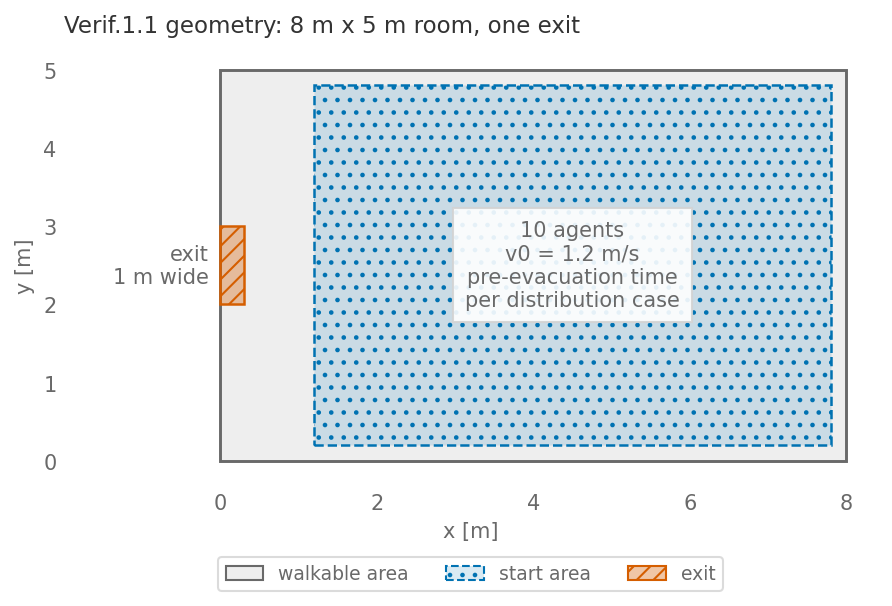

In [7]:
# Scenario geometry as loaded from the ZIP (shared by all four distribution cases).
start = base.distributions["jps-distributions_0"]
params0 = start["parameters"]
minx, miny, maxx, maxy = base.walkable_polygon.bounds
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(7, 4.4))
    handles = vv_draw_scenario(ax, base)
    ax.set_xlim(minx - 2.0, maxx + 0.4)
    c = Polygon(start["coordinates"]).centroid
    ax.text(c.x, c.y, f"{params0['number']} agents\nv0 = {params0['v0']} m/s\n"
            "pre-evacuation time\nper distribution case",
            ha="center", va="center", color="dimgrey",
            bbox={"facecolor": "white", "edgecolor": "lightgrey", "alpha": 0.9, "pad": 6})
    ax.set_xticks(range(0, int(maxx) + 1, 2))
    for ex in base.exits.values():
        e = Polygon(ex["coordinates"])
        ex_minx, ex_miny, ex_maxx, ex_maxy = e.bounds
        ax.text(ex_minx - 0.15, e.centroid.y, f"exit\n{ex_maxy - ex_miny:g} m wide",
                ha="right", va="center", color="dimgrey")
    ax.set_title(f"Verif.1.1 geometry: {maxx - minx:g} m x {maxy - miny:g} m room, one exit", loc="left")
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
    plt.show()

## Sweep the four NIST distributions

`build_variants` deep-copies the base scenario, overrides `premovement_*` via `set_agent_params`, and bumps `max_time` to a value appropriate for the distribution's tail.

In [8]:
runs = {}
for case, variant in build_variants(base):
    result = run_scenario(variant, seed=42)
    df = result.trajectory_dataframe()
    # First non-stationary frame per agent = observed start time.
    starts = []
    for agent_id, sub in df.sort_values(['id', 'frame']).groupby('id'):
        x0, y0 = sub.iloc[0][['x', 'y']]
        moved = sub[(sub.x - x0).abs() + (sub.y - y0).abs() > 0.05]
        t = (moved.iloc[0]['frame'] / result.frame_rate) if len(moved) else float('nan')
        starts.append(t)
    runs[case.name] = {'case': case, 'observed_starts': np.array(starts)}
    result.cleanup()

## Plot observed vs analytic

`sample_reference` re-uses the upstream distribution sampler so the overlay is by definition the same family the loader applied.

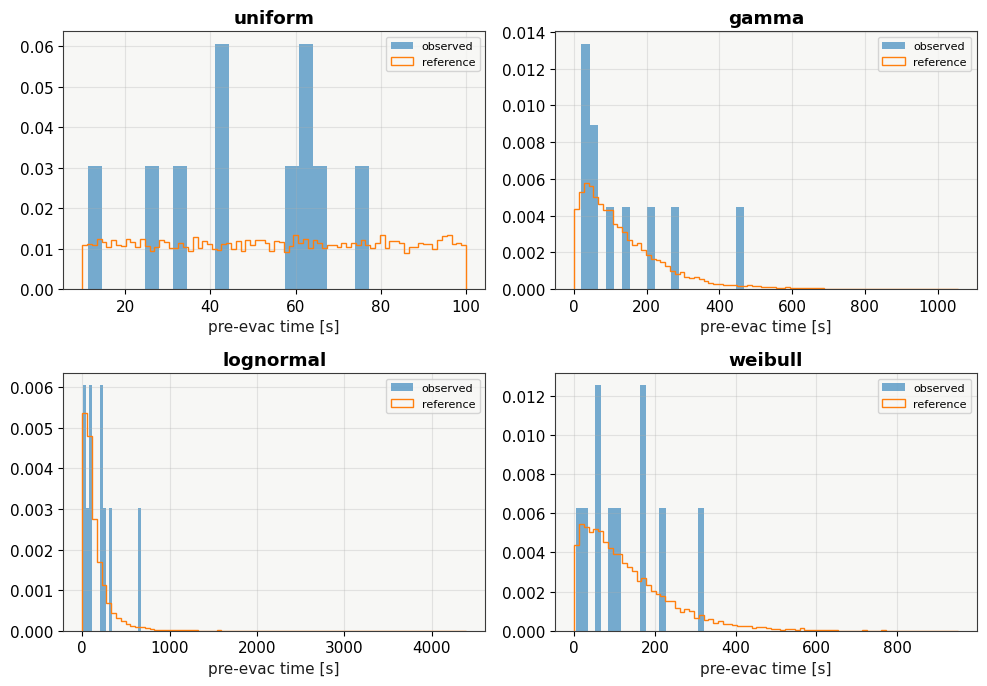

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (name, run) in zip(axes.flat, runs.items()):
    obs = run['observed_starts']
    obs = obs[~np.isnan(obs)]
    if len(obs):
        ax.hist(obs, bins=20, density=True, alpha=0.6, label='observed')
    ref = sample_reference(run['case'], 10000, seed=1)
    ax.hist(ref, bins=80, density=True, histtype='step', label='reference')
    ax.set_title(name)
    ax.set_xlabel('pre-evac time [s]')
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Acceptance

In [10]:
from scipy import stats as _stats
ALPHA = 0.05
rows = []
for name, run in runs.items():
    obs = run['observed_starts']
    obs = obs[~np.isnan(obs)]
    ref = sample_reference(run['case'], 10000, seed=2)
    ks = _stats.ks_2samp(obs, ref) if len(obs) else None
    rows.append({
        'case': name, 'n': int(len(obs)),
        'ks_p': ks.pvalue if ks else float('nan'),
    })
fit = pd.DataFrame(rows)
print(fit)
assert (fit['ks_p'] > ALPHA).all(), fit

        case   n      ks_p
0    uniform  10  0.273241
1      gamma  10  0.834412
2  lognormal  10  0.333898
3    weibull  10  0.997132


## Result figure

Empirical CDF of the observed start times (first frame with movement > 0.05 m) against the analytic CDF of each distribution. Acceptance: two-sample KS test against the reference sampler, p > 0.05.

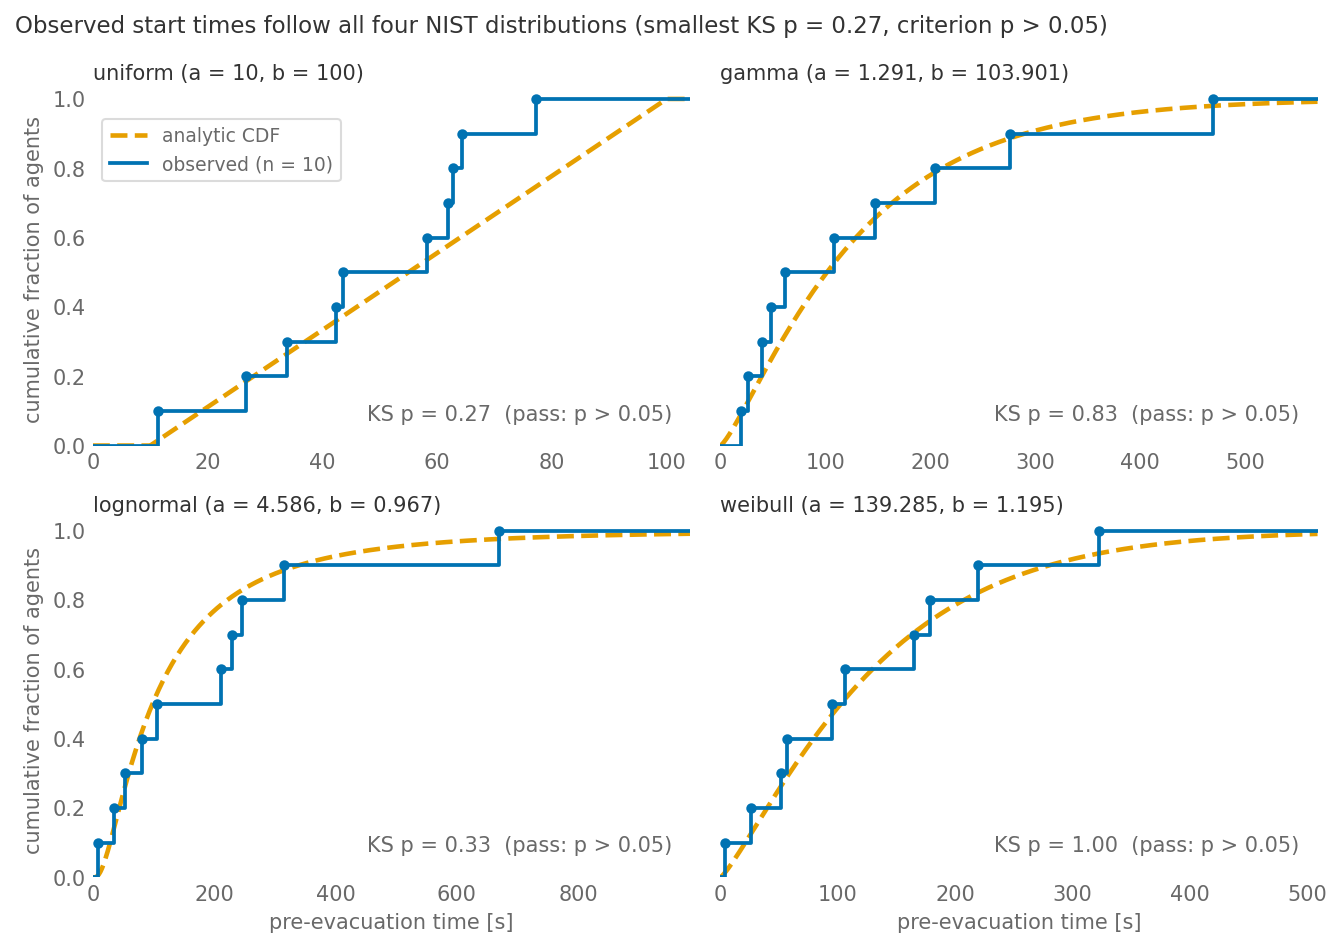

In [11]:
# Observed start times against the analytic CDF of each NIST distribution (same cases as the KS test).
def analytic_cdf(case, x):
    a, b = case.param_a, case.param_b
    if case.name == "uniform":
        return _stats.uniform.cdf(x, loc=a, scale=b - a)
    if case.name == "gamma":
        return _stats.gamma.cdf(x, a, scale=b)
    if case.name == "lognormal":
        return _stats.lognorm.cdf(x, s=b, scale=np.exp(a))
    return _stats.weibull_min.cdf(x, c=b, scale=a)


with plt.rc_context(VV_RC):
    fig, axes = plt.subplots(2, 2, figsize=(9, 6.4), sharey=True)
    for ax, (name, run), p in zip(axes.flat, runs.items(), fit["ks_p"]):
        case = run["case"]
        obs = np.sort(run["observed_starts"][~np.isnan(run["observed_starts"])])
        ref = sample_reference(case, 10000, seed=2)
        xmax = max(np.quantile(ref, 0.99), obs.max()) * 1.05
        xs = np.linspace(0.0, xmax, 400)
        ax.plot(xs, analytic_cdf(case, xs), color=VV_ORANGE, lw=2.2, ls="--", label="analytic CDF")
        ex = np.r_[0.0, obs, xmax]
        ey = np.r_[0.0, np.arange(1, len(obs) + 1) / len(obs), 1.0]
        ax.step(ex, ey, where="post", color=VV_BLUE, lw=1.8, label=f"observed (n = {len(obs)})")
        ax.plot(obs, np.arange(1, len(obs) + 1) / len(obs), "o", color=VV_BLUE, ms=4)
        ax.set_title(f"{name} (a = {case.param_a:g}, b = {case.param_b:g})", loc="left", fontsize=10)
        ax.text(0.97, 0.06, f"KS p = {p:.2f}  (pass: p > {ALPHA})", transform=ax.transAxes,
                ha="right", va="bottom", color="dimgrey")
        ax.set_xlim(0, xmax)
        ax.set_ylim(0, 1.02)
        ax.grid(axis="y")
        ax.grid(axis="x", visible=False)
        if ax in axes[1]:
            ax.set_xlabel("pre-evacuation time [s]")
        if ax in axes[:, 0]:
            ax.set_ylabel("cumulative fraction of agents")
    axes[0, 0].legend(loc="upper left", bbox_to_anchor=(0.0, 0.95))
    fig.suptitle(f"Observed start times follow all four NIST distributions "
                 f"(smallest KS p = {fit['ks_p'].min():.2f}, criterion p > {ALPHA})",
                 x=0.01, ha="left", fontsize=11, color="#333333")
    fig.tight_layout()
    plt.show()